# CSE465 — YOLO11n Baseline (On-the-Fly Augmentation)

This notebook trains **YOLO11n** on the prepared PV-cell defect dataset using:

- Maximum epochs: **50**
- Early stopping patience: **5**
- Image size: **640**
- Batch size: **16**
- Seed: **42**
- **On-the-fly training augmentation**
- Resume support for Google Colab disconnects
- Exact epoch timing
- Final test-set evaluation
- Precision, Recall, F1, mAP50, mAP75, mAP50–95
- Mean matched **bounding-box IoU** and **bounding-box Dice**
- Training/validation loss curves
- Raw and normalized confusion matrices
- Model parameters, GFLOPs, model size, inference time
- Ground-truth vs prediction examples

> **Important:** Augmentation is applied only while loading the **training** images.  
> Validation and test images are not augmented.

> **Controlled comparison:** This notebook uses the same prepared train/val/test split and core training settings as the Aug notebook. Only the requested on-the-fly augmentation policy is changed.

Notebook location recommended:  
`MyDrive/Colab Notebooks/CSE465/02_YOLO11n_Aug.ipynb`

Results are saved under:  
`MyDrive/Study Materials /CSE465/02_YOLO11n_Aug/`


## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Install Ultralytics and verify GPU

In [2]:
!pip install -q -U ultralytics
!pip uninstall -y -q albumentations albucore

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 6.6 MB/s eta 0:00:00


In [3]:
import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not available. In Colab, go to Runtime > Change runtime type > GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics: 8.4.123
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 3. Define project folders

In [4]:
from pathlib import Path

# NOTE: there is a space after 'Study Materials' in this Drive path.
CSE_ROOT = Path("/content/drive/MyDrive/Study Materials /CSE465")
DATA_ZIP = CSE_ROOT / "Prepared Dataset.zip"

EXP_ROOT = CSE_ROOT / "02_YOLO11n_Aug"
WEIGHTS_DIR = EXP_ROOT / "weights"
METRICS_DIR = EXP_ROOT / "metrics"
PLOTS_DIR = EXP_ROOT / "plots"
PREDICTIONS_DIR = EXP_ROOT / "predictions"
CONFIG_DIR = EXP_ROOT / "config"

# Ultralytics will create this folder when training starts.
RAW_RUN_DIR = EXP_ROOT / "raw_run"

for folder in [
    EXP_ROOT,
    WEIGHTS_DIR,
    METRICS_DIR,
    PLOTS_DIR,
    PREDICTIONS_DIR,
    CONFIG_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

assert DATA_ZIP.exists(), f"Dataset ZIP not found: {DATA_ZIP}"

print("Dataset ZIP:", DATA_ZIP)
print("Experiment folder:", EXP_ROOT)


Dataset ZIP: /content/drive/MyDrive/Study Materials /CSE465/Prepared Dataset.zip
Experiment folder: /content/drive/MyDrive/Study Materials /CSE465/02_YOLO11n_Aug


## 4. Extract the dataset to local Colab storage

Training reads images from `/content/` for better I/O performance.  
The original ZIP in Drive remains untouched.

In [5]:
import zipfile
import shutil

LOCAL_ROOT = Path("/content/CSE465_dataset")

if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

print("Extracting dataset...")
with zipfile.ZipFile(DATA_ZIP, "r") as zf:
    zf.extractall(LOCAL_ROOT)

yaml_files = list(LOCAL_ROOT.rglob("data.yaml"))
if not yaml_files:
    raise FileNotFoundError("data.yaml was not found after extraction.")

DATA_YAML = yaml_files[0]
DATASET_DIR = DATA_YAML.parent

print("Dataset directory:", DATASET_DIR)
print("data.yaml:", DATA_YAML)

Extracting dataset...
Dataset directory: /content/CSE465_dataset/Prepared Dataset
data.yaml: /content/CSE465_dataset/Prepared Dataset/data.yaml


## 5. Fix the Windows path inside `data.yaml`

In [6]:
import yaml
import shutil

# Save original YAML for documentation.
shutil.copy2(DATA_YAML, CONFIG_DIR / "original_data.yaml")

with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

# Replace the original Windows path with the Colab-local dataset path.
data_config["path"] = str(DATASET_DIR)

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False, allow_unicode=True)

# Save the exact YAML used for this experiment.
shutil.copy2(DATA_YAML, CONFIG_DIR / "effective_data.yaml")

print(DATA_YAML.read_text())

path: /content/CSE465_dataset/Prepared Dataset
train: images/train
val: images/val
test: images/test
nc: 9
names:
- finger
- crack
- black_core
- thick_line
- horizontal_dislocation
- short_circuit
- vertical_dislocation
- star_crack
- printing_error



## 6. Verify train/validation/test image and label counts

In [7]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

dataset_counts = {}

for split in ["train", "val", "test"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = sorted(
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    )
    labels = sorted(label_dir.glob("*.txt"))

    empty_labels = sum(1 for p in labels if p.read_text().strip() == "")

    dataset_counts[split] = {
        "images": len(images),
        "labels": len(labels),
        "empty_labels": empty_labels,
    }

    print("=" * 50)
    print(split.upper())
    print("Images       :", len(images))
    print("Label files  :", len(labels))
    print("Empty labels :", empty_labels)

    assert len(images) == len(labels), f"{split}: image/label count mismatch!"

print("\nExpected prepared split: train=4418, val=947, test=949")

TRAIN
Images       : 4418
Label files  : 4418
Empty labels : 945
VAL
Images       : 947
Label files  : 947
Empty labels : 203
TEST
Images       : 949
Label files  : 949
Empty labels : 202

Expected prepared split: train=4418, val=947, test=949


## 7. Validate YOLO labels and class IDs

In [8]:
NUM_CLASSES = 9
bad_labels = []

for split in ["train", "val", "test"]:
    label_dir = DATASET_DIR / "labels" / split

    for label_path in label_dir.glob("*.txt"):
        text = label_path.read_text().strip()

        # Empty label = background image.
        if not text:
            continue

        for line in text.splitlines():
            parts = line.split()

            if len(parts) != 5:
                bad_labels.append((str(label_path), "Expected 5 columns", line))
                continue

            try:
                class_id = int(float(parts[0]))
                coords = list(map(float, parts[1:]))
            except Exception:
                bad_labels.append((str(label_path), "Non-numeric annotation", line))
                continue

            if not 0 <= class_id < NUM_CLASSES:
                bad_labels.append((str(label_path), f"Invalid class {class_id}", line))

            if not all(0.0 <= x <= 1.0 for x in coords):
                bad_labels.append((str(label_path), "Coordinate outside [0,1]", line))

if bad_labels:
    print("Annotation problems found:")
    for problem in bad_labels[:20]:
        print(problem)
    raise RuntimeError(f"{len(bad_labels)} annotation problem(s) found.")
else:
    print("All annotations passed validation.")

All annotations passed validation.


## 8. Save dataset summary

In [9]:
summary_path = DATASET_DIR / "dataset_summary.txt"

if summary_path.exists():
    shutil.copy2(summary_path, CONFIG_DIR / "dataset_summary.txt")
    print(summary_path.read_text())
else:
    print("dataset_summary.txt was not found.")

PV Cell Defect Dataset - final distribution
Note: class rows are IMAGE counts containing that class, not box
counts, and one image can contain more than one class, so class
rows can add up to more than the TOTAL row.

class                       train     val    test   total
---------------------------------------------------------
finger                        786     177     187    1150
crack                         812     179     185    1176
black_core                    702     150     150    1002
thick_line                    697     149     149     995
horizontal_dislocation        555     119     119     793
short_circuit                 525     112     113     750
vertical_dislocation           71      15      16     102
star_crack                    139      30      30     199
printing_error                  4       1       0       5
good                          630     135     135     900
material                      315      68      67     450
----------------------------

## 9. Training configuration

In [10]:
import platform
import yaml
import torch
import ultralytics

BASE_WEIGHTS = "yolo11n.pt"

IMAGE_SIZE = 640
BATCH_SIZE = 16
NUM_WORKERS = 2

MAX_EPOCHS = 50
PATIENCE = 5
RANDOM_SEED = 42

CACHE_IMAGES = False
DROPOUT_RATE = 0.0

training_config = {
    "experiment": "YOLO11n_Aug",
    "model": BASE_WEIGHTS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "workers": NUM_WORKERS,
    "maximum_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "seed": RANDOM_SEED,
    "dropout": DROPOUT_RATE,
    "augmentation": "ON - on-the-fly",
    "train_images": dataset_counts["train"]["images"],
    "val_images": dataset_counts["val"]["images"],
    "test_images": dataset_counts["test"]["images"],
}

with open(CONFIG_DIR / "training_config.yaml", "w") as f:
    yaml.safe_dump(training_config, f, sort_keys=False)

environment_text = f'''
Experiment: YOLO11n On-the-Fly Augmentation
Ultralytics: {ultralytics.__version__}
PyTorch: {torch.__version__}
Python: {platform.python_version()}
GPU: {torch.cuda.get_device_name(0)}

Image size: {IMAGE_SIZE}
Batch size: {BATCH_SIZE}
Maximum epochs: {MAX_EPOCHS}
Patience: {PATIENCE}
Seed: {RANDOM_SEED}
'''

(CONFIG_DIR / "environment.txt").write_text(environment_text.strip())
print(environment_text)



Experiment: YOLO11n On-the-Fly Augmentation
Ultralytics: 8.4.123
PyTorch: 2.11.0+cu128
Python: 3.12.13
GPU: Tesla T4

Image size: 640
Batch size: 16
Maximum epochs: 50
Patience: 5
Seed: 42



## 10. On-the-fly augmentation configuration

This run uses the same **on-the-fly augmentation policy** used in the earlier YOLO11n augmented experiment:

- Brightness/value (`hsv_v`): **0.4**
- Rotation: **±5°**
- Translation: **0.10**
- Scale: **0.30**
- Shear: **±2°**
- Vertical flip probability: **0.50**
- Horizontal flip probability: **0.50**
- Mosaic: **1.0**
- MixUp: **0.10**
- Random erasing setting: **0.40**

Hue and saturation changes remain disabled because the PV EL images are essentially grayscale.

These transformations are generated **during training only**; no augmented images are written into the dataset.  
The earlier separate offline rare-class oversampling/copy-paste step is **not** used here, so the prepared dataset remains unchanged.


In [11]:
AUGMENTATION = {
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.4,

    "degrees": 5.0,
    "translate": 0.10,
    "scale": 0.30,
    "shear": 2.0,
    "perspective": 0.0,

    "flipud": 0.50,
    "fliplr": 0.50,

    "mosaic": 1.0,
    "mixup": 0.10,

    # Not part of this controlled on-the-fly policy:
    "cutmix": 0.0,
    "copy_paste": 0.0,
    "multi_scale": 0.0,

    # Keep Mosaic active rather than automatically disabling it near the end.
    "close_mosaic": 0,

    # Avoid additional automatic policies outside this explicit configuration.
    "auto_augment": None,

    # Retained from the previous augmentation configuration.
    # Ultralytics currently treats this primarily as a classification augmentation.
    "erasing": 0.40,
}

with open(CONFIG_DIR / "augmentation_config.yaml", "w") as f:
    yaml.safe_dump(AUGMENTATION, f, sort_keys=False)

print("YOLO11n on-the-fly augmentation enabled.")
print(AUGMENTATION)


YOLO11n on-the-fly augmentation enabled.
{'hsv_h': 0.0, 'hsv_s': 0.0, 'hsv_v': 0.4, 'degrees': 5.0, 'translate': 0.1, 'scale': 0.3, 'shear': 2.0, 'perspective': 0.0, 'flipud': 0.5, 'fliplr': 0.5, 'mosaic': 1.0, 'mixup': 0.1, 'cutmix': 0.0, 'copy_paste': 0.0, 'multi_scale': 0.0, 'close_mosaic': 0, 'auto_augment': None, 'erasing': 0.4}


## 11. Exact epoch timing callbacks

Times are saved to Google Drive after every completed epoch so a Colab disconnect does not erase timing history.

In [12]:
import time
import pandas as pd
import torch

EPOCH_TIMES_CSV = METRICS_DIR / "epoch_times.csv"
epoch_records = {}

if EPOCH_TIMES_CSV.exists():
    existing = pd.read_csv(EPOCH_TIMES_CSV)
    for _, row in existing.iterrows():
        epoch_records[int(row["epoch"])] = row.to_dict()
    print("Loaded existing timing records:", len(epoch_records))


def synchronize_gpu():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def on_train_epoch_start(trainer):
    synchronize_gpu()
    now = time.perf_counter()
    trainer._cse_train_start = now
    trainer._cse_fit_start = now


def on_train_epoch_end(trainer):
    synchronize_gpu()

    epoch = trainer.epoch + 1
    train_seconds = time.perf_counter() - trainer._cse_train_start

    epoch_records.setdefault(epoch, {})
    epoch_records[epoch]["epoch"] = epoch
    epoch_records[epoch]["train_seconds"] = train_seconds


def on_fit_epoch_end(trainer):

    if not hasattr(trainer, "_cse_fit_start"):
        return

    epoch = trainer.epoch + 1

    # Ignore Ultralytics' final best.pt validation
    if (
        epoch not in epoch_records
        or "train_seconds" not in epoch_records[epoch]
    ):
        return

    if (
        "fit_seconds" in epoch_records[epoch]
        and pd.notna(epoch_records[epoch]["fit_seconds"])
    ):
        return

    synchronize_gpu()

    fit_seconds = time.perf_counter() - trainer._cse_fit_start
    train_seconds = epoch_records[epoch]["train_seconds"]
    validation_seconds = max(0.0, fit_seconds - train_seconds)

    epoch_records[epoch]["fit_seconds"] = fit_seconds
    epoch_records[epoch]["validation_seconds"] = validation_seconds

    pd.DataFrame(
        [epoch_records[k] for k in sorted(epoch_records)]
    ).to_csv(EPOCH_TIMES_CSV, index=False)

    print(
        f"\nEpoch {epoch} timing | "
        f"Train: {train_seconds/60:.2f} min | "
        f"Val: {validation_seconds/60:.2f} min | "
        f"Total: {fit_seconds/60:.2f} min"
    )

## 12. Check for an interrupted run

In [13]:
LAST_PT = RAW_RUN_DIR / "weights" / "last.pt"
BEST_PT = RAW_RUN_DIR / "weights" / "best.pt"

print("Existing last.pt:", LAST_PT.exists())
print("Existing best.pt:", BEST_PT.exists())

if LAST_PT.exists():
    print("\nExisting checkpoint found. Use the RESUME cell, not fresh training.")
else:
    print("\nNo existing checkpoint found. Fresh training can begin.")

Existing last.pt: False
Existing best.pt: False

No existing checkpoint found. Fresh training can begin.


# 13. Model training

## 13A. Fresh training

**Run this cell only for the first session.**  
If Colab disconnects and `last.pt` exists, use Cell 13B instead.

In [14]:
from ultralytics import YOLO

if LAST_PT.exists():
    raise RuntimeError(
        "Existing last.pt detected. Use the resume cell instead of starting over."
    )

model = YOLO(BASE_WEIGHTS)

model.add_callback("on_train_epoch_start", on_train_epoch_start)
model.add_callback("on_train_epoch_end", on_train_epoch_end)
model.add_callback("on_fit_epoch_end", on_fit_epoch_end)

train_results = model.train(
    data=str(DATA_YAML),

    epochs=MAX_EPOCHS,
    patience=PATIENCE,

    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,

    device=0,
    workers=NUM_WORKERS,
    cache=CACHE_IMAGES,
    amp=True,

    seed=RANDOM_SEED,
    deterministic=True,
    dropout=DROPOUT_RATE,

    val=True,
    save=True,

    # Save every completed epoch.
    save_period=1,

    plots=True,

    project=str(EXP_ROOT),
    name="raw_run",
    exist_ok=False,

    **AUGMENTATION,
)


Ultralytics 8.4.123 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=None, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/CSE465_dataset/Prepared Dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=raw_run, nbs=64, nms

## 13B. Resume after a Colab disconnect

After reconnecting to a GPU, rerun Cells 1–12, **skip Cell 13A**, then run this cell.

In [ ]:
from ultralytics import YOLO

assert LAST_PT.exists(), f"No resume checkpoint found: {LAST_PT}"

print("Resuming from:", LAST_PT)

resume_model = YOLO(str(LAST_PT))

resume_model.add_callback("on_train_epoch_start", on_train_epoch_start)
resume_model.add_callback("on_train_epoch_end", on_train_epoch_end)
resume_model.add_callback("on_fit_epoch_end", on_fit_epoch_end)

resume_results = resume_model.train(resume=True)

# Post-training analysis
Run the remaining cells only after training finishes or early stopping occurs.

## 14. Organize final training outputs

In [15]:
import shutil
import pandas as pd

RAW_BEST = RAW_RUN_DIR / "weights" / "best.pt"
RAW_LAST = RAW_RUN_DIR / "weights" / "last.pt"
RAW_RESULTS = RAW_RUN_DIR / "results.csv"
RAW_ARGS = RAW_RUN_DIR / "args.yaml"

assert RAW_BEST.exists(), "best.pt was not found."

shutil.copy2(RAW_BEST, WEIGHTS_DIR / "best.pt")

if RAW_LAST.exists():
    shutil.copy2(RAW_LAST, WEIGHTS_DIR / "last.pt")

if RAW_RESULTS.exists():
    shutil.copy2(RAW_RESULTS, METRICS_DIR / "results.csv")

if RAW_ARGS.exists():
    shutil.copy2(RAW_ARGS, CONFIG_DIR / "ultralytics_args.yaml")

TRAINING_PLOTS_DIR = PLOTS_DIR / "training"
TRAINING_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

for extension in ["*.png", "*.jpg"]:
    for file in RAW_RUN_DIR.glob(extension):
        shutil.copy2(file, TRAINING_PLOTS_DIR / file.name)

print("Training outputs organized.")

Training outputs organized.


## 15. Read training history and identify best epoch

In [16]:
results_df = pd.read_csv(METRICS_DIR / "results.csv")
results_df.columns = [col.strip() for col in results_df.columns]

display(results_df.tail())
print("\nColumns:")
print(results_df.columns.tolist())

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
29,30,2848.09,0.90868,0.73418,1.06702,0.81373,0.84453,0.88855,0.57416,0.91562,3.66301,0.84124,0.000327,0.000327,0.000327
30,31,2941.17,0.91139,0.74008,1.06356,0.81221,0.88696,0.90510,0.57536,0.94785,4.86257,0.85986,0.000312,0.000312,0.000312
31,32,3034.06,0.87705,0.70796,1.05160,0.83918,0.86874,0.90529,0.57806,0.92274,4.47258,0.84001,0.000297,0.000297,0.000297
32,33,3126.88,0.88317,0.69635,1.05618,0.83262,0.86658,0.89128,0.57154,0.90636,3.43549,0.83851,0.000282,0.000282,0.000282
33,34,3219.65,0.88195,0.71363,1.06022,0.82246,0.85192,0.89213,0.55327,0.95287,3.10507,0.87752,0.000267,0.000267,0.000267



Columns:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


In [17]:
map5095_columns = [
    c for c in results_df.columns
    if "mAP50-95" in c
]

if not map5095_columns:
    raise RuntimeError("mAP50-95 column could not be found.")

MAP5095_COL = map5095_columns[0]

epoch_values = results_df["epoch"].astype(int).copy()
if epoch_values.min() == 0:
    epoch_values = epoch_values + 1

results_df["display_epoch"] = epoch_values

best_idx = results_df[MAP5095_COL].idxmax()
best_epoch = int(results_df.loc[best_idx, "display_epoch"])
epochs_completed = int(results_df["display_epoch"].max())
stopped_early = epochs_completed < MAX_EPOCHS

print("Maximum epochs :", MAX_EPOCHS)
print("Completed      :", epochs_completed)
print("Best epoch     :", best_epoch)
print("Stopped early  :", stopped_early)
print("Best val mAP50-95:", float(results_df.loc[best_idx, MAP5095_COL]))

Maximum epochs : 50
Completed      : 34
Best epoch     : 29
Stopped early  : True
Best val mAP50-95: 0.57935


## 16. Training and validation loss vs epoch

,epoch,train_box_loss,val_box_loss,train_cls_loss,val_cls_loss,train_dfl_loss,val_dfl_loss,train_total_loss,val_total_loss
29,30,0.90868,0.91562,0.73418,3.66301,1.06702,0.84124,2.70988,5.41987
30,31,0.91139,0.94785,0.74008,4.86257,1.06356,0.85986,2.71503,6.67028
31,32,0.87705,0.92274,0.70796,4.47258,1.05160,0.84001,2.63661,6.23533
32,33,0.88317,0.90636,0.69635,3.43549,1.05618,0.83851,2.63570,5.18036
33,34,0.88195,0.95287,0.71363,3.10507,1.06022,0.87752,2.65580,4.93546


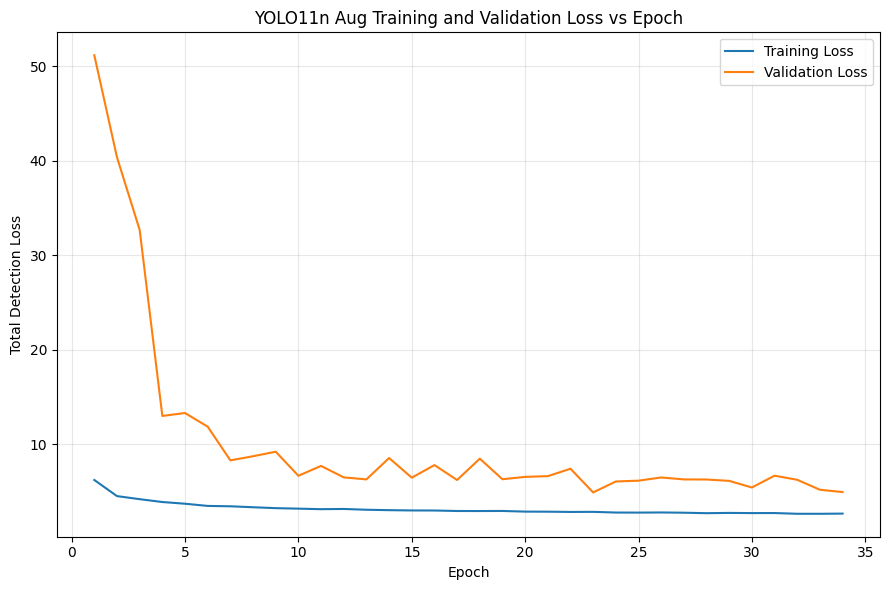

Saved: /content/drive/MyDrive/Study Materials /CSE465/02_YOLO11n_Aug/plots/training_validation_loss_vs_epochs.png


In [18]:
import matplotlib.pyplot as plt
import pandas as pd

epochs = results_df["display_epoch"].values

required_loss_cols = [
    "train/box_loss", "train/cls_loss", "train/dfl_loss",
    "val/box_loss", "val/cls_loss", "val/dfl_loss",
]

missing = [c for c in required_loss_cols if c not in results_df.columns]
if missing:
    raise RuntimeError(f"Missing expected loss columns: {missing}")

train_total_loss = (
    results_df["train/box_loss"]
    + results_df["train/cls_loss"]
    + results_df["train/dfl_loss"]
)

val_total_loss = (
    results_df["val/box_loss"]
    + results_df["val/cls_loss"]
    + results_df["val/dfl_loss"]
)

loss_df = pd.DataFrame({
    "epoch": epochs,
    "train_box_loss": results_df["train/box_loss"],
    "val_box_loss": results_df["val/box_loss"],
    "train_cls_loss": results_df["train/cls_loss"],
    "val_cls_loss": results_df["val/cls_loss"],
    "train_dfl_loss": results_df["train/dfl_loss"],
    "val_dfl_loss": results_df["val/dfl_loss"],
    "train_total_loss": train_total_loss,
    "val_total_loss": val_total_loss,
})

loss_df.to_csv(METRICS_DIR / "loss_vs_epochs.csv", index=False)
display(loss_df.tail())

plt.figure(figsize=(9, 6))
plt.plot(epochs, train_total_loss, label="Training Loss")
plt.plot(epochs, val_total_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Total Detection Loss")
plt.title("YOLO11n Aug Training and Validation Loss vs Epoch")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

loss_plot_path = PLOTS_DIR / "training_validation_loss_vs_epochs.png"
plt.savefig(loss_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", loss_plot_path)

## 17. Individual box/classification/DFL loss curves

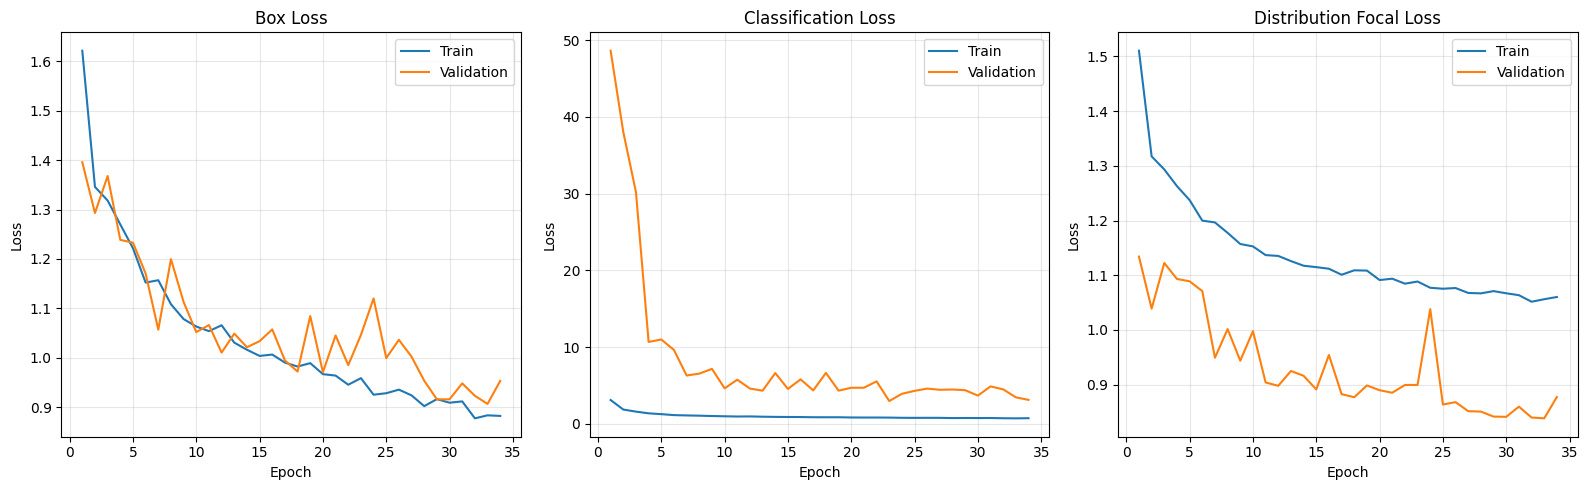

Saved: /content/drive/MyDrive/Study Materials /CSE465/02_YOLO11n_Aug/plots/individual_loss_curves.png


In [19]:
loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box Loss"),
    ("train/cls_loss", "val/cls_loss", "Classification Loss"),
    ("train/dfl_loss", "val/dfl_loss", "Distribution Focal Loss"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (train_col, val_col, title) in zip(axes, loss_pairs):
    ax.plot(epochs, results_df[train_col], label="Train")
    ax.plot(epochs, results_df[val_col], label="Validation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
individual_loss_path = PLOTS_DIR / "individual_loss_curves.png"
plt.savefig(individual_loss_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", individual_loss_path)

## 18. Exact training-time summary

In [20]:
timing_df = pd.read_csv(EPOCH_TIMES_CSV)

mean_train_seconds = timing_df["train_seconds"].mean()
mean_validation_seconds = timing_df["validation_seconds"].mean()
mean_fit_seconds = timing_df["fit_seconds"].mean()
total_fit_seconds = timing_df["fit_seconds"].sum()

print(f"Mean training time/epoch : {mean_train_seconds/60:.2f} min")
print(f"Mean validation time/epoch: {mean_validation_seconds/60:.2f} min")
print(f"Mean train+val time/epoch: {mean_fit_seconds/60:.2f} min")
print(f"Total completed epoch time: {total_fit_seconds/60:.2f} min")

history_with_time = pd.merge(
    results_df,
    timing_df,
    left_on="display_epoch",
    right_on="epoch",
    how="left",
    suffixes=("_ultralytics", "_timing"),
)

history_with_time.to_csv(
    METRICS_DIR / "training_history_with_time.csv",
    index=False,
)

Mean training time/epoch : 1.39 min
Mean validation time/epoch: 0.19 min
Mean train+val time/epoch: 1.58 min
Total completed epoch time: 53.67 min


## 19. Load `best.pt` and collect model complexity

In [21]:
from ultralytics import YOLO
import pandas as pd

FINAL_BEST = WEIGHTS_DIR / "best.pt"
best_model = YOLO(str(FINAL_BEST))

info_out = best_model.info(detailed=False, verbose=True, imgsz=IMAGE_SIZE)

# Current Ultralytics typically returns (layers, params, gradients, GFLOPs).
if isinstance(info_out, tuple) and len(info_out) >= 4:
    layers, parameters, gradients, gflops = info_out[:4]
else:
    layers = parameters = gradients = gflops = None

model_size_mb = FINAL_BEST.stat().st_size / (1024 ** 2)

model_info_df = pd.DataFrame([{
    "model": "YOLO11n",
    "experiment": "Aug",
    "layers": layers,
    "parameters": parameters,
    "parameters_M": (parameters / 1e6) if parameters is not None else None,
    "GFLOPs": gflops,
    "model_size_MB": model_size_mb,
    "epochs_completed": epochs_completed,
    "best_epoch": best_epoch,
    "mean_train_sec_per_epoch": mean_train_seconds,
    "mean_train_val_sec_per_epoch": mean_fit_seconds,
    "total_train_val_seconds": total_fit_seconds,
}])

model_info_df.to_csv(METRICS_DIR / "model_info.csv", index=False)
display(model_info_df)

YOLO11n summary: 182 layers, 2,591,595 parameters, 0 gradients, 6.5 GFLOPs


,model,experiment,layers,parameters,parameters_M,GFLOPs,model_size_MB,epochs_completed,best_epoch,mean_train_sec_per_epoch,mean_train_val_sec_per_epoch,total_train_val_seconds
0,YOLO11n,Aug,182,2591595,2.591595,6.508186,5.219812,34,29,83.608163,94.714957,3220.308524


## 20. Final evaluation on the test split

This evaluates only the final `best.pt` checkpoint on the 949-image test set.
`plots=True` generates confusion matrices and PR/P/R/F1 curves.

In [22]:
test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",

    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,

    device=0,
    workers=NUM_WORKERS,

    plots=True,

    project=str(PLOTS_DIR),
    name="test_evaluation",
    exist_ok=True,
)

Ultralytics 8.4.123 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,583,907 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 23.8±22.8 MB/s, size: 91.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/CSE465_dataset/Prepared Dataset/labels/test... 949 images, 202 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 949/949 654.6it/s 1.4s
val: New cache created: /content/CSE465_dataset/Prepared Dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 4.8it/s 12.5s
                   all        949       1502      0.802       0.83       0.87      0.554
                finger        187        385      0.845      0.904      0.928      0.489
                 crack        185        231      0.593 

## 21. Standard test metrics

In [23]:
import numpy as np
import pandas as pd

test_precision = float(test_metrics.box.mp)
test_recall = float(test_metrics.box.mr)
test_map50 = float(test_metrics.box.map50)
test_map75 = float(test_metrics.box.map75)
test_map50_95 = float(test_metrics.box.map)

test_f1 = (
    2 * test_precision * test_recall / (test_precision + test_recall)
    if (test_precision + test_recall) > 0
    else 0.0
)

print("Precision :", round(test_precision, 4))
print("Recall    :", round(test_recall, 4))
print("F1        :", round(test_f1, 4))
print("mAP50     :", round(test_map50, 4))
print("mAP75     :", round(test_map75, 4))
print("mAP50-95  :", round(test_map50_95, 4))

Precision : 0.8022
Recall    : 0.8303
F1        : 0.816
mAP50     : 0.8704
mAP75     : 0.5245
mAP50-95  : 0.5537


## 22. Save per-class metrics

In [24]:
try:
    per_class_summary = test_metrics.summary(normalize=True, decimals=6)
    per_class_df = pd.DataFrame(per_class_summary)
except Exception as e:
    print("test_metrics.summary() unavailable; using box arrays instead:", e)

    names = data_config["names"]
    maps = np.asarray(test_metrics.box.maps)

    # Per-class P/R/F1 arrays are normally available in box.p/r/f1.
    p_arr = np.asarray(getattr(test_metrics.box, "p", np.full(len(names), np.nan)))
    r_arr = np.asarray(getattr(test_metrics.box, "r", np.full(len(names), np.nan)))
    f1_arr = np.asarray(getattr(test_metrics.box, "f1", np.full(len(names), np.nan)))

    per_class_df = pd.DataFrame({
        "class_id": list(range(len(names))),
        "class_name": names,
        "precision": p_arr[:len(names)],
        "recall": r_arr[:len(names)],
        "F1": f1_arr[:len(names)],
        "mAP50_95": maps[:len(names)],
    })

per_class_df.to_csv(
    METRICS_DIR / "test_per_class_metrics.csv",
    index=False,
)

display(per_class_df)

,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95
0,finger,187,385,0.845020,0.903896,0.873467,0.928102,0.488755
1,crack,185,231,0.593215,0.694433,0.639846,0.699839,0.434298
2,black_core,150,152,0.966527,0.940789,0.953485,0.977811,0.896583
3,thick_line,149,167,0.919795,0.634731,0.751126,0.856509,0.414610
4,horizontal_dislocation,119,357,0.676229,0.988796,0.803174,0.851886,0.370304
5,short_circuit,113,113,0.895760,0.991150,0.941044,0.961661,0.947453
6,vertical_dislocation,16,64,0.810970,0.670365,0.733995,0.843933,0.426366
7,star_crack,30,33,0.710411,0.818182,0.760498,0.843623,0.451570


## 23. Verify and display normalized confusion matrix

Raw confusion matrix exists: True
Normalized confusion matrix exists: True


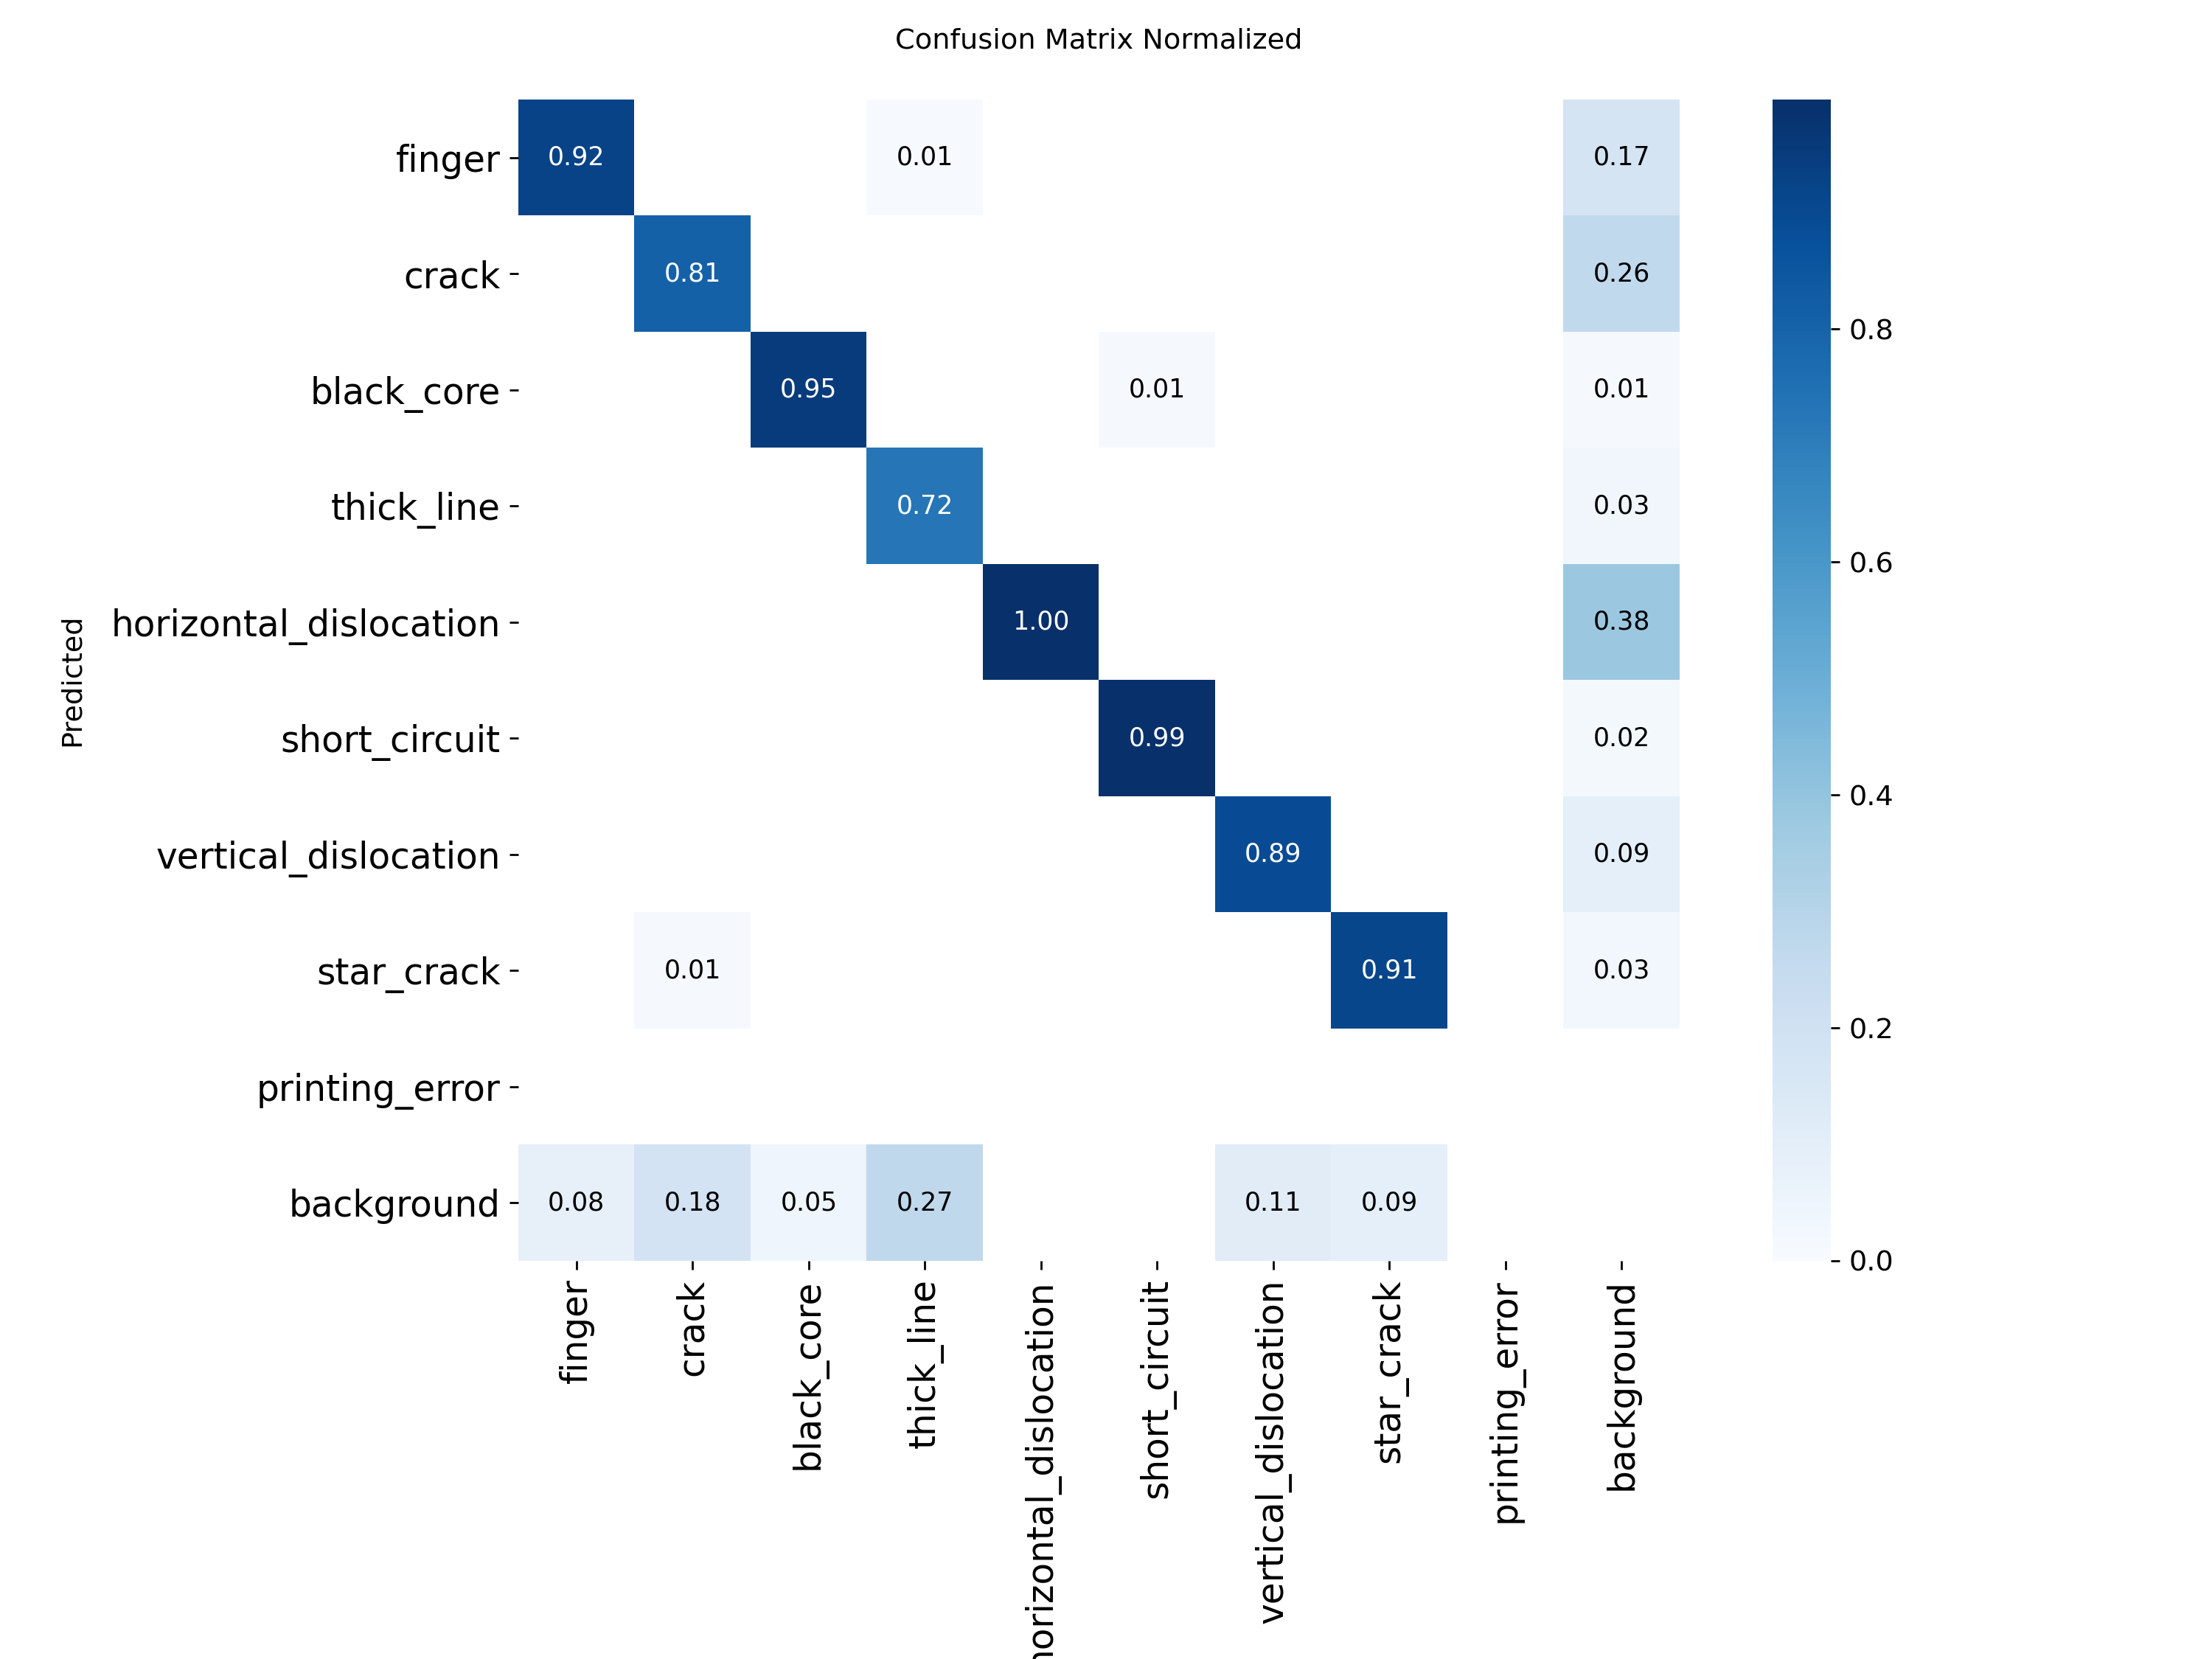

In [25]:
from IPython.display import Image, display

TEST_EVAL_DIR = PLOTS_DIR / "test_evaluation"
RAW_CM = TEST_EVAL_DIR / "confusion_matrix.png"
NORMALIZED_CM = TEST_EVAL_DIR / "confusion_matrix_normalized.png"

print("Raw confusion matrix exists:", RAW_CM.exists())
print("Normalized confusion matrix exists:", NORMALIZED_CM.exists())

if NORMALIZED_CM.exists():
    display(Image(filename=str(NORMALIZED_CM)))
else:
    print("Normalized confusion matrix was not found.")

## 24. Simple Bounding-Box IoU and Dice Evaluation


In [26]:
# Reload a clean model for evaluation

import gc
import torch
from ultralytics import YOLO

if "best_model" in globals():
    del best_model

gc.collect()
torch.cuda.empty_cache()

best_model = YOLO(str(WEIGHTS_DIR / "best.pt"))

print("Fresh best.pt loaded.")
print(f"CUDA allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

Fresh best.pt loaded.
CUDA allocated: 0.11 GB


In [27]:
# Simple Bounding-Box IoU and Dice Evaluation

import numpy as np
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

CONF = 0.25
MATCH_IOU = 0.50

TEST_IMG = DATASET_DIR / "images" / "test"
TEST_LBL = DATASET_DIR / "labels" / "test"


# ---------- IoU ----------
def calc_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0


# ---------- Ground-truth reader ----------
def load_gt(label_path, w, h):

    boxes = []

    if not label_path.exists():
        return boxes

    for line in label_path.read_text().strip().splitlines():

        if not line.strip():
            continue

        cls, xc, yc, bw, bh = map(float, line.split())

        xc *= w
        yc *= h
        bw *= w
        bh *= h

        boxes.append([
            int(cls),
            [
                xc - bw/2,
                yc - bh/2,
                xc + bw/2,
                yc + bh/2
            ]
        ])

    return boxes


ious = []

image_paths = sorted(
    p for p in TEST_IMG.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)


# ---------- Test images ----------
for img_path in tqdm(image_paths, desc="Calculating IoU/Dice"):

    with Image.open(img_path) as im:
        w, h = im.size

    gt = load_gt(
        TEST_LBL / f"{img_path.stem}.txt",
        w, h
    )

    result = best_model.predict(
        source=str(img_path),
        imgsz=IMAGE_SIZE,
        conf=CONF,
        batch=1,
        device=0,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is not None:

        for box, cls in zip(
            result.boxes.xyxy.cpu().numpy(),
            result.boxes.cls.cpu().numpy()
        ):
            predictions.append([
                int(cls),
                box
            ])

    # Class-aware one-to-one matching
    used_gt = set()

    for pred_cls, pred_box in predictions:

        best_iou = 0
        best_gt = None

        for j, (gt_cls, gt_box) in enumerate(gt):

            if j in used_gt or pred_cls != gt_cls:
                continue

            iou = calc_iou(pred_box, gt_box)

            if iou > best_iou:
                best_iou = iou
                best_gt = j

        if best_gt is not None and best_iou >= MATCH_IOU:

            used_gt.add(best_gt)
            ious.append(best_iou)


# ---------- Final results ----------
mean_iou = np.mean(ious) if ious else 0

# Dice derived from each matched bounding-box IoU
dices = [2 * x / (1 + x) for x in ious]
mean_dice = np.mean(dices) if dices else 0

print("\n===== Bounding-Box Overlap Results =====")
print(f"Matched boxes : {len(ious)}")
print(f"Mean IoU      : {mean_iou:.4f}")
print(f"Mean Dice     : {mean_dice:.4f}")

Calculating IoU/Dice:   0%|          | 0/949 [00:00<?, ?it/s]


===== Bounding-Box Overlap Results =====
Matched boxes : 1361
Mean IoU      : 0.7855
Mean Dice     : 0.8754


## 25. Ground Truth v Model Prediction

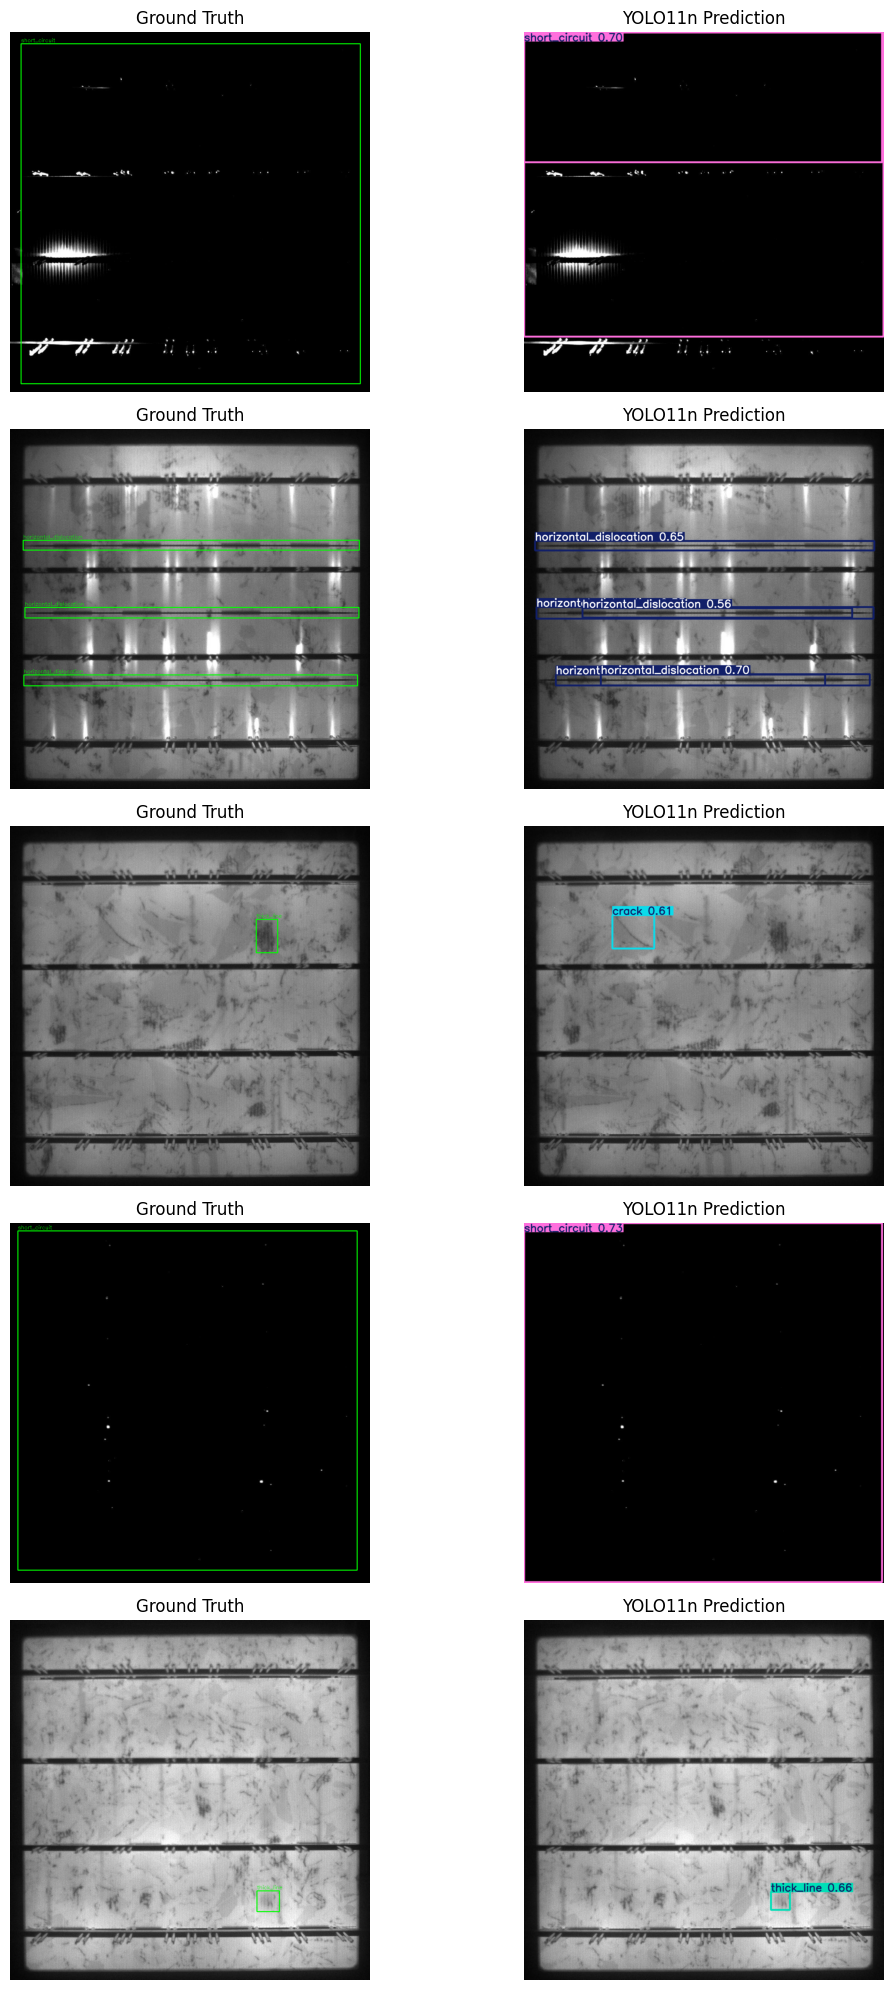

Saved: /content/drive/MyDrive/Study Materials /CSE465/02_YOLO11n_Aug/plots/ground_truth_vs_prediction.png


In [28]:
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Paths
IMG_DIR = DATASET_DIR / "images" / "test"
LBL_DIR = DATASET_DIR / "labels" / "test"

classes = best_model.names

# Select test images that contain defects
images = []

for p in IMG_DIR.iterdir():
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        label = LBL_DIR / f"{p.stem}.txt"

        if label.exists() and label.read_text().strip():
            images.append(p)

# Randomly select 6 images
random.seed(42)
samples = random.sample(images, min(5, len(images)))

# Predict
results = best_model.predict(
    source=[str(p) for p in samples],
    imgsz=IMAGE_SIZE,
    conf=0.25,
    device=0,
    verbose=False
)

fig, axes = plt.subplots(
    len(samples),
    2,
    figsize=(12, 4 * len(samples))
)

for i, (img_path, result) in enumerate(zip(samples, results)):

    # -------------------------
    # Ground Truth
    # -------------------------
    gt = cv2.imread(str(img_path))
    h, w = gt.shape[:2]

    label_path = LBL_DIR / f"{img_path.stem}.txt"

    for line in label_path.read_text().splitlines():

        cls, xc, yc, bw, bh = map(float, line.split())

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(
            gt,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            gt,
            classes[int(cls)],
            (x1, max(15, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1
        )

    gt = cv2.cvtColor(gt, cv2.COLOR_BGR2RGB)

    # -------------------------
    # Model Prediction
    # -------------------------
    pred = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    axes[i, 0].imshow(gt)
    axes[i, 0].set_title("Ground Truth")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(pred)
    axes[i, 1].set_title("YOLO11n Prediction")
    axes[i, 1].axis("off")

plt.tight_layout()

# Save to Drive
save_path = PLOTS_DIR / "ground_truth_vs_prediction.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

# 26. Final Model Summary

In [29]:
# FINAL YOLO11n AUGMENTED MODEL SUMMARY
# Uses results already calculated above — no retraining or re-evaluation.

import pandas as pd
import numpy as np

# -----------------------------
# Inference speed
# -----------------------------
if "test_metrics" in globals():
    inference_ms = float(test_metrics.speed.get("inference", np.nan))
    preprocess_ms = float(test_metrics.speed.get("preprocess", np.nan))
    postprocess_ms = float(test_metrics.speed.get("postprocess", np.nan))
else:
    inference_ms = preprocess_ms = postprocess_ms = np.nan

fps = 1000 / inference_ms if inference_ms > 0 else np.nan


# -----------------------------
# Overall model summary
# -----------------------------
final_summary_df = pd.DataFrame([{

    "Model": "YOLO11n",
    "Experiment": "Aug",

    # Training
    "Epochs Completed": epochs_completed,
    "Best Epoch": best_epoch,
    "Early Stopped": stopped_early,

    # Detection performance
    "Precision": test_precision,
    "Recall": test_recall,
    "F1": test_f1,
    "mAP@50": test_map50,
    "mAP@75": test_map75,
    "mAP@50-95": test_map50_95,

    # Bounding-box overlap
    "Mean Box IoU": float(mean_iou),
    "Mean Box Dice": float(mean_dice),
    "Matched Boxes": len(ious),

    # Complexity
    "Parameters (M)": float(model_info_df.loc[0, "parameters_M"]),
    "GFLOPs": float(model_info_df.loc[0, "GFLOPs"]),
    "Model Size (MB)": float(model_info_df.loc[0, "model_size_MB"]),

    # Training time
    "Mean Train Time/Epoch (min)": mean_train_seconds / 60,
    "Mean Val Time/Epoch (min)": mean_validation_seconds / 60,
    "Mean Train+Val/Epoch (min)": mean_fit_seconds / 60,
    "Total Training Time (min)": total_fit_seconds / 60,

    # Inference
    "Preprocess (ms/image)": preprocess_ms,
    "Inference (ms/image)": inference_ms,
    "Postprocess (ms/image)": postprocess_ms,
    "FPS": fps,
}]).round(4)


print("=" * 70)
print("YOLO11n AUGMENTED — FINAL MODEL SUMMARY")
print("=" * 70)

display(final_summary_df)


# -----------------------------
# Per-class performance
# -----------------------------
print("\nPER-CLASS TEST PERFORMANCE")
display(per_class_df.round(4))


# -----------------------------
# Save final tables
# -----------------------------
final_summary_df.to_csv(
    METRICS_DIR / "final_model_summary.csv",
    index=False
)

per_class_df.to_csv(
    METRICS_DIR / "final_per_class_summary.csv",
    index=False
)

print("\nSaved:")
print(METRICS_DIR / "final_model_summary.csv")
print(METRICS_DIR / "final_per_class_summary.csv")

YOLO11n AUGMENTED — FINAL MODEL SUMMARY


,Model,Experiment,Epochs Completed,Best Epoch,Early Stopped,Precision,Recall,F1,mAP@50,mAP@75,...,GFLOPs,Model Size (MB),Mean Train Time/Epoch (min),Mean Val Time/Epoch (min),Mean Train+Val/Epoch (min),Total Training Time (min),Preprocess (ms/image),Inference (ms/image),Postprocess (ms/image),FPS
0,YOLO11n,Aug,34,29,True,0.8022,0.8303,0.816,0.8704,0.5245,...,6.5082,5.2198,1.3935,0.1851,1.5786,53.6718,2.0203,4.0923,1.6207,244.3617



PER-CLASS TEST PERFORMANCE


,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95
0,finger,187,385,0.8450,0.9039,0.8735,0.9281,0.4888
1,crack,185,231,0.5932,0.6944,0.6398,0.6998,0.4343
2,black_core,150,152,0.9665,0.9408,0.9535,0.9778,0.8966
3,thick_line,149,167,0.9198,0.6347,0.7511,0.8565,0.4146
4,horizontal_dislocation,119,357,0.6762,0.9888,0.8032,0.8519,0.3703
5,short_circuit,113,113,0.8958,0.9912,0.9410,0.9617,0.9475
6,vertical_dislocation,16,64,0.8110,0.6704,0.7340,0.8439,0.4264
7,star_crack,30,33,0.7104,0.8182,0.7605,0.8436,0.4516



Saved:
/content/drive/MyDrive/Study Materials /CSE465/02_YOLO11n_Aug/metrics/final_model_summary.csv
/content/drive/MyDrive/Study Materials /CSE465/02_YOLO11n_Aug/metrics/final_per_class_summary.csv
